In [100]:
illimuminated_pixel_0 = (7, 10)
illimuminated_pixel_1 = (7, 11)
illimuminated_pixel_0_zs = [(6, 12), (6,12), (7,10), (7,10), (7,10)]
illimuminated_pixel_1_zs = [(7, 10), (7,10), (7,11), (7,11), (7,11)]

z_steps = 5
x_steps = 36

In [2]:
def extract_zx(filename):
    splitting = filename.split('_')
    z = splitting[1]
    x = splitting[3]
    return (int(z),int(x))

In [3]:
from pathlib import Path
from aare import RawFile
import numpy as np
import matplotlib.pyplot as plt
import os
import scipy

In [4]:
#base = Path('/data_pool/data/pollux202610/z_scan_780eV_10_5_5slits_focus_scan3')
base = Path('/data_pool/data/pollux202610/z_scan_780eV_10_5_5slits_focus_scan_strixel')
files = os.listdir(base)
data_files = [f for f in files if f.endswith('.json')]
pedestal_file = 'dark_master_985.json'
data_files.remove(pedestal_file)

In [5]:
for fname in base.iterdir():
    continue
    print(fname)

In [6]:
f = RawFile(base / data_files[0])
R = 1
headers, data = f.read()
del headers
# data has an ROI
len_y = data.shape[2]
len_x = data.shape[1]
# print(data.shape)
del data

In [7]:
pedestal = np.empty((len_x, len_y), dtype=np.uint16)
with RawFile(base / pedestal_file, chunk_size=100) as f:
            for header, data in f:
                del header
                pedestal = np.mean(data, axis=0)

In [8]:
print(pedestal)

[[ 1734.02  1370.58  1486.84  1540.91  1731.71  1332.34  1502.86  1861.38
   1306.62  1425.34  1536.67  1637.44  1176.12  1428.81  1407.31  1610.1
   1644.27  1564.26  1605.82]
 [ 1529.47  1649.39   586.75 58784.44  1667.76  1271.45  1650.22  1690.59
   1358.44  1207.17  1695.69  1507.72  1408.21  1265.63  1484.21  1577.25
   1881.61  1385.05  1567.81]
 [ 1396.33 58611.53  1768.15  1695.47  1539.21  1509.76  1485.46  1774.54
   1241.09  1248.26  1724.52  1473.18  1505.16  1578.04  1323.14  1479.75
   1640.91  1395.55  1699.02]
 [ 1537.96  1452.71  1451.91  1683.84  1537.33  1501.72  1558.4   1515.06
   1440.32  1342.14  1835.54  1267.46  1311.99  1502.33  1422.04  1484.08
   1404.43  1560.66  1673.13]
 [ 1456.97  1474.58  1250.62  1553.58  1414.94  1475.47  1591.93  1465.46
   1412.98  1639.86  1745.64  1368.04  1317.54  1628.3   1629.27  1623.4
   1724.99  1746.6   1670.42]
 [ 1213.77  1527.63  1532.11  1456.97  1384.85  1405.16  1367.05  1533.95
   1268.12  1223.8   1579.86  1402.97 

In [97]:
for i, fname in enumerate(data_files):
    if 'z_24000' in fname:
        print(f'{i}: {fname}')

0: z_24000_y_-1535_master_1143.json
17: z_24000_y_-1532_master_1146.json
23: z_24000_y_-1528_master_1150.json
31: z_24000_y_-1521_master_1157.json
33: z_24000_y_-1526_master_1152.json
36: z_24000_y_-1517_master_1161.json
39: z_24000_y_-1543_master_1135.json
44: z_24000_y_-1544_master_1134.json
51: z_24000_y_-1531_master_1147.json
56: z_24000_y_-1538_master_1140.json
61: z_24000_y_-1540_master_1138.json
63: z_24000_y_-1529_master_1149.json
65: z_24000_y_-1536_master_1142.json
76: z_24000_y_-1525_master_1153.json
79: z_24000_y_-1522_master_1156.json
83: z_24000_y_-1513_master_1165.json
85: z_24000_y_-1547_master_1131.json
92: z_24000_y_-1514_master_1164.json
96: z_24000_y_-1542_master_1136.json
97: z_24000_y_-1516_master_1162.json
107: z_24000_y_-1527_master_1151.json
112: z_24000_y_-1518_master_1160.json
119: z_24000_y_-1545_master_1133.json
124: z_24000_y_-1534_master_1144.json
128: z_24000_y_-1520_master_1158.json
130: z_24000_y_-1519_master_1159.json
132: z_24000_y_-1533_master_1145.

In [98]:
file_number = 92
f = RawFile(base / data_files[file_number])
print(data_files[file_number])
headers, data = f.read()

z_24000_y_-1514_master_1164.json


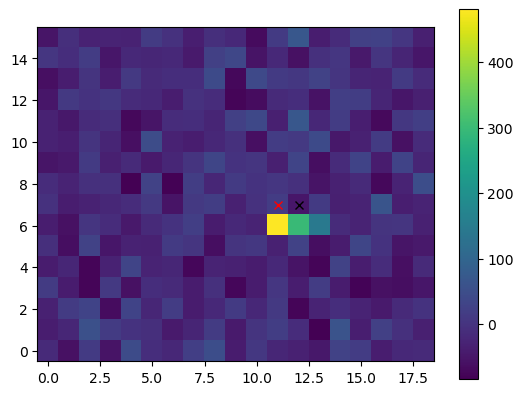

In [86]:
plt.imshow(data[2,:,:] - pedestal, origin='lower')
plt.plot(*illimuminated_pixel_0[::-1], marker='x', color='r')
plt.plot(*illimuminated_pixel_1[::-1], marker='x', color='k')
plt.colorbar()
plt.show()

# print(data[0,7,8])

In [12]:
(data[1,:,:] - pedestal)[*illimuminated_pixel_0]

np.float64(58.559999999999945)

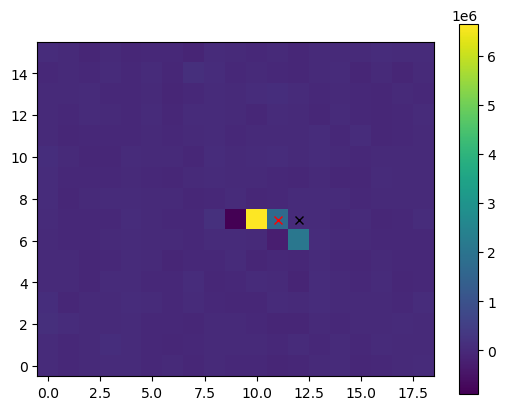

In [99]:
offset_subtracted = data - pedestal
acc = offset_subtracted.sum(axis=0)

plt.imshow(acc, origin='lower')
plt.plot(*illimuminated_pixel_0[::-1], marker='x', color='r')
plt.plot(*illimuminated_pixel_1[::-1], marker='x', color='k')
plt.colorbar()
plt.show()

In [14]:
z_pos_intensity = np.zeros(len(data_files), dtype=np.uint16)
z_pos_intensity

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0], dtype=uint16)

In [104]:
z_pos_intensity = np.zeros(len(data_files))
z_pos_intensity_2 = np.zeros(len(data_files))
z_pos_intensity_3 = np.zeros(len(data_files))
z_pos_std = np.zeros(len(data_files))
z_pos_std_2 = np.zeros(len(data_files))

coordinates = np.zeros((len(data_files), 2))

for k, filename in enumerate(sorted(data_files)):
    f = RawFile(base / filename)
    # R = 5000
    headers, data = f.read()
    del headers
    data = (data - pedestal).astype(np.uint16)
    
    coordinates[k] = extract_zx(filename)
    
    z_pos_intensity[k] = np.sum(data[:,*illimuminated_pixel_0_zs[k//x_steps]])/R  #data[0,7,8]
    z_pos_intensity_2[k] = np.sum(data[:,*illimuminated_pixel_1_zs[k//x_steps]])/R
    z_pos_std[k] = np.std(data[:,*illimuminated_pixel_0])
    z_pos_std_2[k] = np.std(data[:,*illimuminated_pixel_1])
    # z_pos_intensity = np.sum(data[:,6:8,7:9])/R 
            


In [103]:
36//36

1

In [76]:
print(len(coordinates))

180


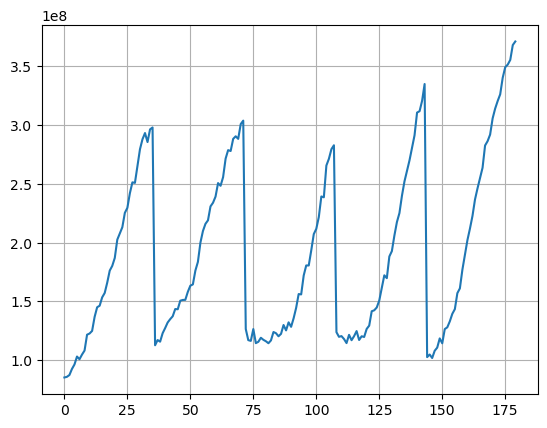

In [105]:
# plt.errorbar(x=range(len(z_pos_intensity_2)),y=z_pos_intensity_2, yerr=z_pos_std_2)
plt.plot(z_pos_intensity)
plt.grid()
plt.show()

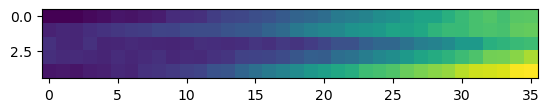

In [106]:
intensity_1_image = z_pos_intensity.reshape(z_steps, x_steps)
plt.imshow(intensity_1_image)

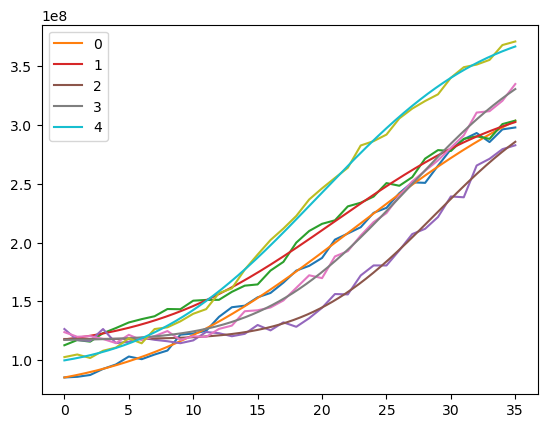

In [161]:
from scipy.optimize import curve_fit
from scipy.special import erf

sigmas = np.zeros(z_steps)
for g in range(z_steps):
    x = np.arange(36)
    y = intensity_1_image[g]
    plt.plot(intensity_1_image[g])
    # Error function to fit
    def error_function(x, A, B, mu, sigma):
        return A + B * erf((x - mu) / (np.sqrt(2) * sigma))
    
    # Initial guesses for the parameters
    initial_guess = [
        np.min(y),              # A
        (np.max(y) - np.min(y))/2,  # B
        np.mean(x),             # mu
        np.std(x)               # sigma
    ]
    # Fit the data
    popt, pcov = curve_fit(
        error_function,
        x,
        y,
        p0=initial_guess,
        maxfev=10000
    )
    
    # Extract fitted parameters
    A_fit, B_fit, mu_fit, sigmas[g] = popt
    x_fit = np.linspace(np.min(x), np.max(x), 1000)
    y_fit = error_function(x_fit, *popt)
    plt.plot(x_fit,y_fit, label=g)
    plt.legend()

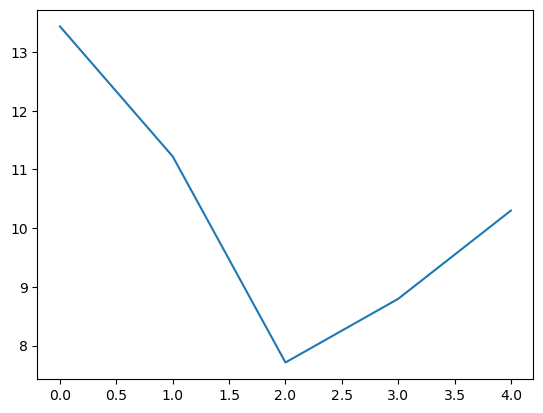

In [132]:
plt.plot(sigmas)

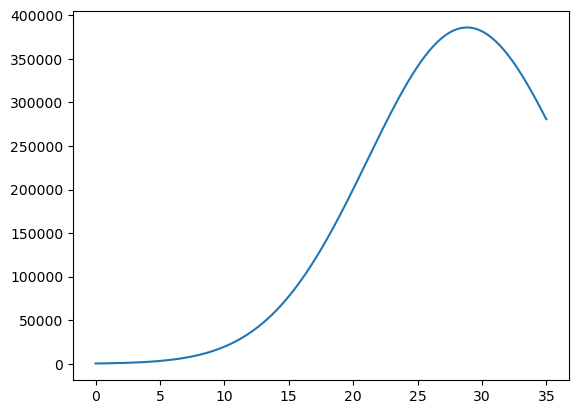

In [126]:
plt.plot(x_fit,np.gradient(y_fit))

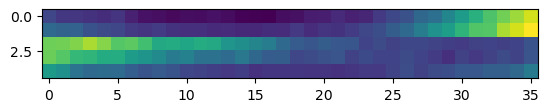

In [107]:
intensity_2_image = z_pos_intensity_2.reshape(z_steps, x_steps)
plt.imshow(intensity_2_image)

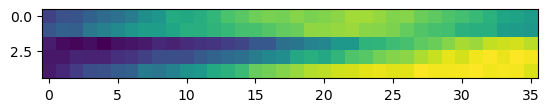

In [108]:
plt.imshow(intensity_1_image/(intensity_2_image + intensity_1_image))

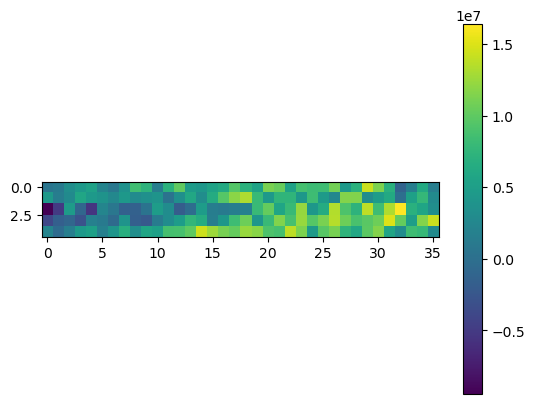

In [109]:
im = plt.imshow(np.gradient(intensity_1_image, axis=1))
plt.colorbar(im)

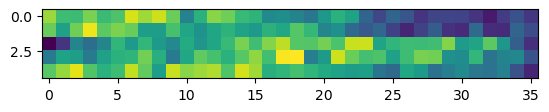

In [110]:
plt.imshow(np.gradient(intensity_1_image/(intensity_2_image + intensity_1_image), axis=1))

(array([2.83619469]), array([7417448.25]), array([28.04773416]), array([30.88392885]))
(array([4.25444725]), array([6755205.25]), array([15.10449384]), array([19.35894109]))
(array([2.38554489]), array([9854390.75]), array([30.30657807]), array([32.69212296]))
(array([2.84186517]), array([9983181.75]), array([29.21117627]), array([32.05304144]))
(array([12.41128243]), array([8712924.25]), array([10.97850056]), array([23.38978299]))


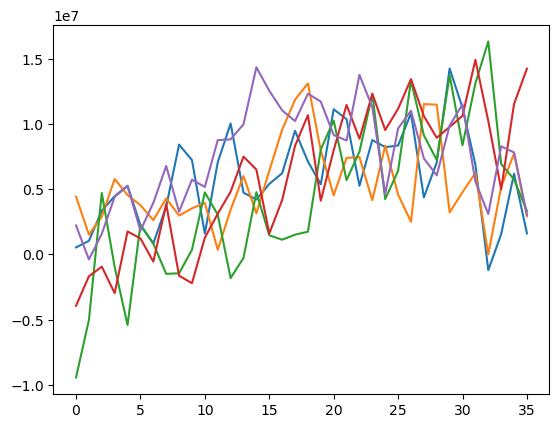

In [111]:
fig, ax = plt.subplots()
widths = np.zeros(15)
for i, line_data in enumerate(np.gradient(intensity_1_image, axis=1)):
    ax.plot(line_data + i * 0.01 )
    peak_widths = scipy.signal.peak_widths(line_data, [np.argmax(line_data)])
    widths[i] = peak_widths[0][0]
    print(peak_widths)

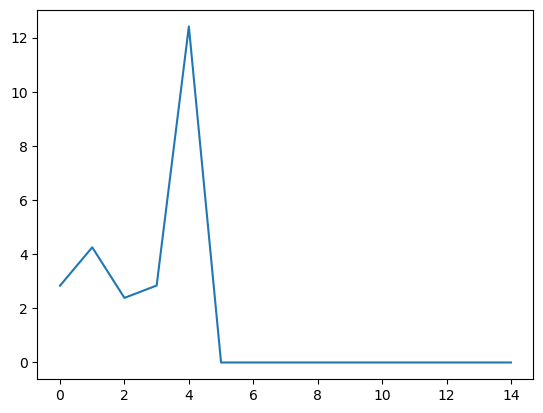

In [112]:
plt.plot(widths)

21011.936959763243


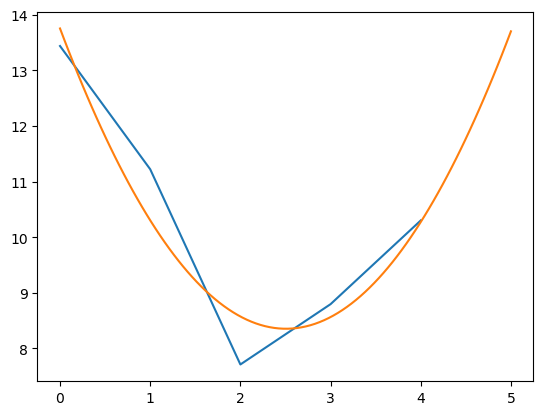

In [160]:
x_fit = np.linspace(0,z_steps, num=100)
x = np.arange(z_steps)
a = np.polyfit(x=x,y=sigmas, deg=2)
plt.plot(sigmas)
plt.plot(x_fit, a[0]*x_fit**2 + a[1]*x_fit + a[2])
print(-a[1]/(2*a[0])*2000+16000)

In [163]:
sigmas[int(-a[1]/(2*a[0]))]

np.float64(7.712351893517531)

In [26]:
coordinates

array([[16000., -1513.],
       [16000., -1514.],
       [16000., -1515.],
       [16000., -1516.],
       [16000., -1517.],
       [16000., -1518.],
       [16000., -1519.],
       [16000., -1520.],
       [16000., -1521.],
       [16000., -1522.],
       [16000., -1523.],
       [16000., -1524.],
       [16000., -1525.],
       [16000., -1526.],
       [16000., -1527.],
       [16000., -1528.],
       [16000., -1529.],
       [16000., -1530.],
       [16000., -1531.],
       [16000., -1532.],
       [16000., -1533.],
       [16000., -1534.],
       [16000., -1535.],
       [16000., -1536.],
       [16000., -1537.],
       [16000., -1538.],
       [16000., -1539.],
       [16000., -1540.],
       [16000., -1541.],
       [16000., -1542.],
       [16000., -1543.],
       [16000., -1544.],
       [16000., -1545.],
       [16000., -1546.],
       [16000., -1547.],
       [16000., -1548.],
       [18000., -1513.],
       [18000., -1514.],
       [18000., -1515.],
       [18000., -1516.],
